<a href="https://colab.research.google.com/github/dairxp/Py-Colab-ALD/blob/main/02_Machine_Learning_PCA_Analisis_de_Componente_Principales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##**Reducción de la Dimensionalidad**

Cuanto mayor es la varianza (proyección dispersa de los puntos), se conserva la mayor cantidad de información y a menor varianza se pierde la mayor cantidad.

Recordemos el álgebra lineal: Los Eigenvectores (o vectores propios) son vectores no nulos que, al ser transformados por una matriz, no cambian su dirección, solo su magnitud. Los eigenvalores (o valores propios) son los escalares (<em>&lambda;</em>) que multiplican a estos vectores, indicando cuánto se estiran, contraen o invierten. Se define por la ecuación <b>Ax=&lambda;x</b>.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [ ]:
ingreso = np.random.uniform(1300, 3500, size=40)
horas_laborales = np.random.uniform(40, 48, size=40)
ingreso, horas_laborales

(array([1569.9186841 , 2175.9662227 , 2178.9736071 , 3032.36849199,
        2421.82310074, 1406.85559979, 1704.925557  , 2983.59563336,
        2496.59994745, 1417.60153073, 2349.54672911, 3356.93515611,
        2092.84247598, 2679.9222969 , 3245.62190971, 3330.93537108,
        1606.75591605, 1664.00202733, 2134.14775694, 2948.11516967,
        1801.90757222, 2243.23914801, 3433.8894164 , 2573.02778953,
        1769.99008341, 2390.1556932 , 3228.11700775, 2190.94674521,
        3116.98110623, 1884.03553118, 2285.46455165, 2327.17245815,
        1422.05541971, 1642.3421894 , 3420.60820044, 3444.84508988,
        3256.12993913, 2640.79141911, 2579.83051452, 2402.46444479]),
 array([40.29037391, 45.74312568, 47.21196521, 45.25487953, 40.03402255,
        45.27009805, 40.57453046, 46.99209966, 43.86450871, 43.45321804,
        42.79054398, 40.51296866, 43.53538578, 44.3576364 , 45.11833438,
        45.64799888, 40.17719634, 46.69461268, 45.82152436, 41.40779271,
        43.29700392, 46.71

In [ ]:
datos = pd.DataFrame({'ingreso': ingreso, 'horas_laborales': horas_laborales})
datos.head()

,ingreso,horas_laborales
0,1569.918684,40.290374
1,2175.966223,45.743126
2,2178.973607,47.211965
3,3032.368492,45.254880
4,2421.823101,40.034023


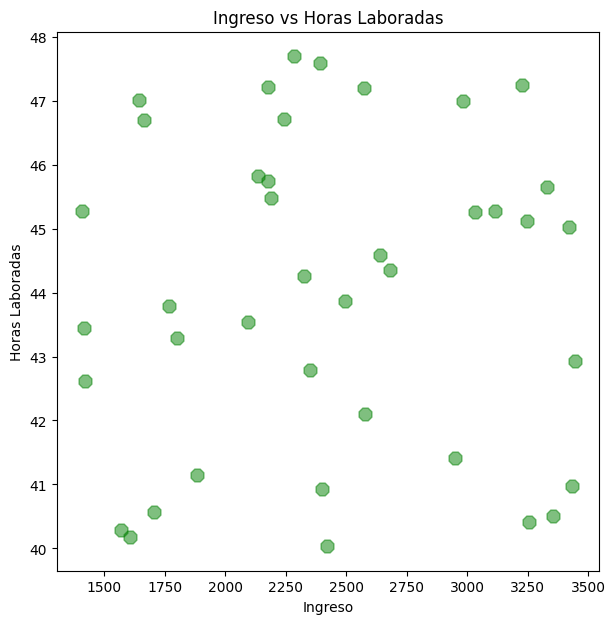

In [ ]:
fig = plt.figure(figsize=(7, 7))
plt.scatter(datos['ingreso'], datos['horas_laborales'], marker='8', s=100, color='green', alpha=.5)
plt.xlabel('Ingreso')
plt.ylabel('Horas Laboradas')
plt.title('Ingreso vs Horas Laboradas')
plt.show()

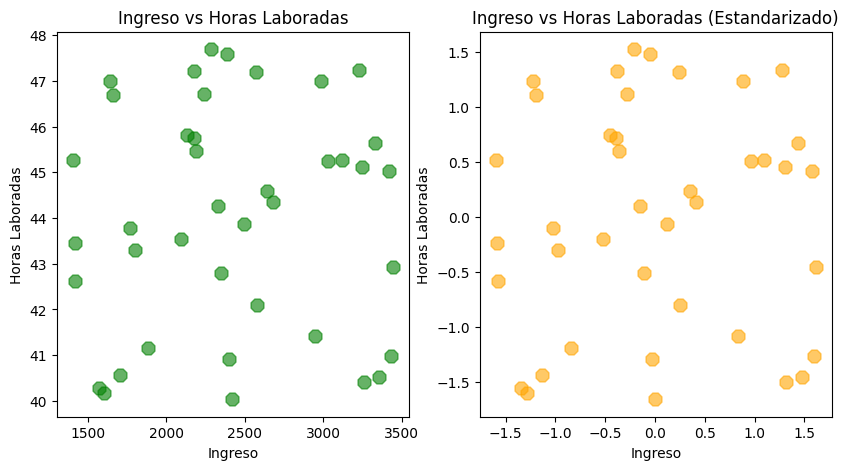

In [ ]:
# PASO 1: Estandarizar los datos

# Recordemos
# Datos_Estandarizados = (punto - promedio)/desviacion_estandar

fig = plt.figure(figsize=(10, 5))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)

ax1.set_title('Ingreso vs Horas Laboradas', fontsize=12)
ax1.scatter(datos['ingreso'], datos['horas_laborales'], marker='8', s=100, color='green', alpha=.6)
ax1.set_xlabel('Ingreso', fontsize=10)
ax1.set_ylabel('Horas Laboradas', fontsize=10)

# Estandarizando los datos
datos_estandarizados = pd.DataFrame(StandardScaler().fit_transform(datos), columns=[['ingreso','horas_laborales']])

ax2.set_title('Ingreso vs Horas Laboradas (Estandarizado)', fontsize=12)
ax2.scatter(datos_estandarizados['ingreso'], datos_estandarizados['horas_laborales'], marker='8', s=100, color='orange', alpha=.6)
ax2.set_xlabel('Ingreso', fontsize=10)
ax2.set_ylabel('Horas Laboradas', fontsize=10)

plt.show()

                  ingreso horas_laborales
ingreso          1.025641        0.036954
horas_laborales  0.036954        1.025641


Text(33.081597222222214, 0.5, '')

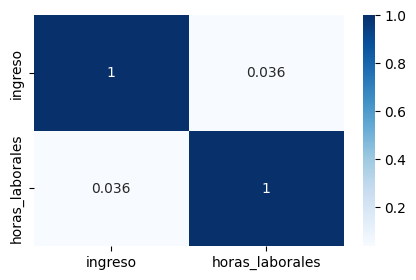

In [ ]:
# Paso 2: Calcular la Matriz de covarianza
print(datos_estandarizados.cov())

plt.figure(figsize=(5, 3))
sns.heatmap(datos_estandarizados.corr(), annot=True, cmap='Blues')
plt.xlabel('')
plt.ylabel('')

Text(0, 0.5, 'Horas Laboradas')

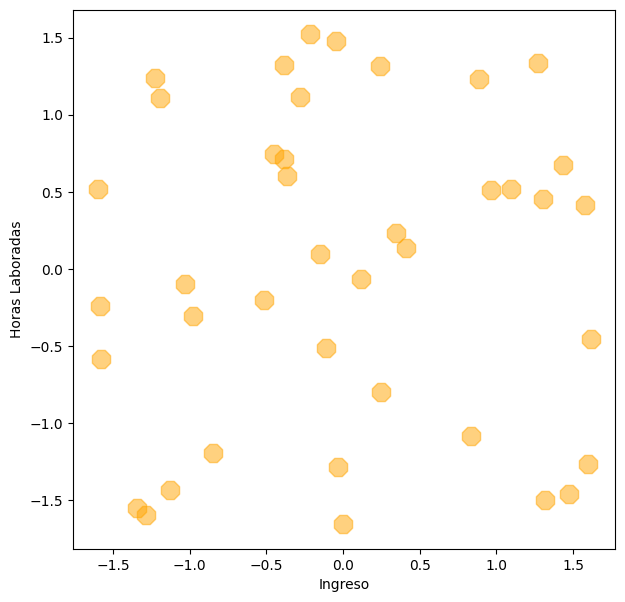

In [ ]:
plt.figure(figsize=(7, 7))
plt.scatter(datos_estandarizados['ingreso'], datos_estandarizados['horas_laborales'], marker='8', s=200, color='orange', alpha=.5)
plt.xlabel('Ingreso')
plt.ylabel('Horas Laboradas')

Eigenvector rojo: [-0.70710678  0.70710678] Eigenvalor: 0.9886869445019927
Eigenvector azul: [0.70710678 0.70710678] Eigenvalor: 1.062595106780058


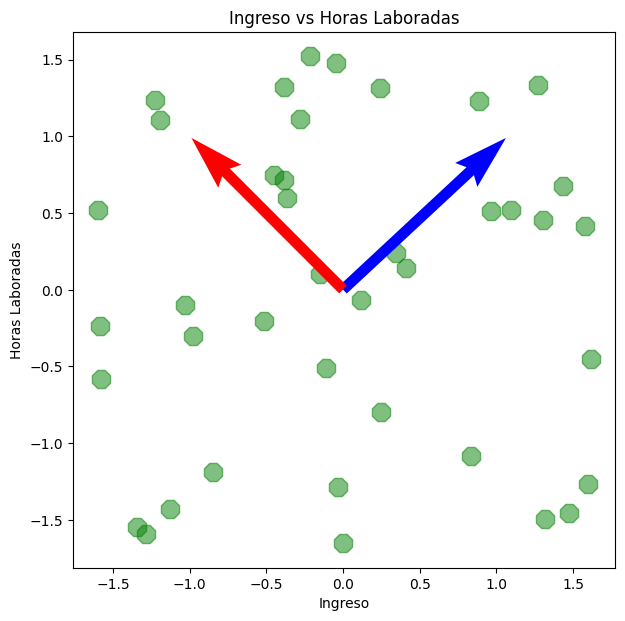

In [ ]:
# Paso 3: Los Eigenvectores y Eigenvalores

from numpy.linalg import eig

valores, vectores = eig(datos_estandarizados.cov())

vector_rojo = vectores[:, 1]
vector_azul = vectores[:, 0]
print('Eigenvector rojo:',vector_rojo, 'Eigenvalor:', valores[1])
print('Eigenvector azul:',vector_azul, 'Eigenvalor:', valores[0])

# Visualizando los vectores
plt.figure(figsize=(7, 7))
plt.axes().set_aspect('equal')

# Mostrando los datos
plt.scatter(datos_estandarizados['ingreso'], datos_estandarizados['horas_laborales'], marker='8', s=200, color='green', alpha=.5)

# Graficando los vectores
plt.quiver(0,0,
           vector_azul[0]/abs(vector_azul[0])*valores[0],
           vector_azul[1]/abs(vector_azul[1])*valores[1],
           scale=1, color='blue', angles='xy', scale_units='xy', width=.02)

plt.quiver(0,0,
           vector_rojo[0]/abs(vector_rojo[0])*valores[1],
           vector_rojo[1]/abs(vector_rojo[1])*valores[1],
           scale=1, color='red', angles='xy', scale_units='xy', width=.02)

plt.xlabel('Ingreso')
plt.ylabel('Horas Laboradas')
plt.title('Ingreso vs Horas Laboradas')
plt.show()

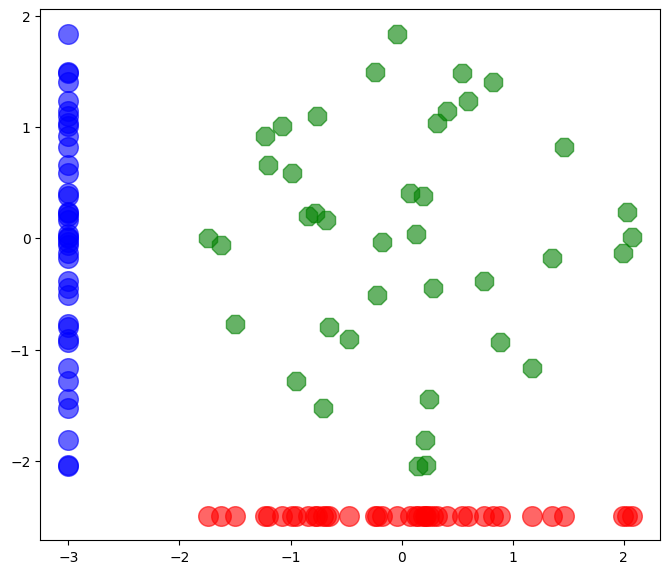

In [ ]:
# Paso 4: Proyección de los datos

# Rotando los datos
proyectado = pd.DataFrame(datos_estandarizados.values @ vectores.T,
                          columns=['ingreso','horas_laborales'])

fig = plt.figure(figsize=(8, 8))
plt.axes().set_aspect('equal')

# Datos rotados
plt.scatter(proyectado['ingreso'], proyectado['horas_laborales'], marker='8', s=200, color='green', alpha=.6)

# Proyección de los datos en una sola dimensión
plt.scatter(proyectado['ingreso'], [-2.5]*len(proyectado['ingreso']), s=200, color='red', alpha=.6)

plt.scatter([-3]*len(proyectado['horas_laborales']), proyectado['horas_laborales'], s=200, color='blue', alpha=.6)

plt.show()

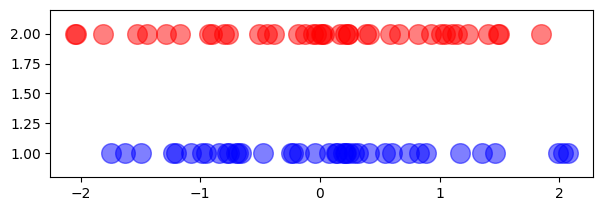

Varianza explicada por cada componente: [1.06259511 0.98868694]
Proporción de varianza explicada por cada componente: [0.51801511 0.48198489]


In [ ]:
# Paso 5: Seleccion de los componentes
from sklearn.decomposition import PCA

# Obtención de los componentes principales
pca = PCA()
datos_pca = pca.fit_transform(datos_estandarizados)

# Código de visualización
plt.figure(figsize=(7, 7))
plt.axes().set_aspect("equal")
plt.scatter(datos_pca[:, 0], [2]*datos_pca[:, 0].size, s=200, color="red", alpha=0.5)
plt.scatter(datos_pca[:, 1], [1]*datos_pca[:, 1].size, s=200, color="blue", alpha=0.5)
plt.ylim((0.8, 2.2))
plt.show()

print("Varianza explicada por cada componente:", pca.explained_variance_)
print("Proporción de varianza explicada por cada componente:", pca.explained_variance_ratio_)